In [2]:
import numpy as np
import os
import cv2
import pandas as pd
import tensorflow as tf
from tensorflow.keras.applications import Xception
from tensorflow.keras.layers import GlobalAveragePooling2D, Lambda
from tensorflow.keras.models import Model

In [4]:
# Define paths to the folders
import numpy as np
import os
import cv2
import pandas as pd
real_videos_path = "D:\\Deepfake_Datasets\\combined_dataset\\real"
deepfake_videos_path = 'D:\\Deepfake_Datasets\\combined_dataset\\fake'

# Initialize lists to store file names and labels
file_names = []
labels = []

# Label real videos with 0
for video in os.listdir(real_videos_path):
    file_names.append(os.path.join(real_videos_path, video))
    labels.append(0)

# Label deepfake videos with 1
for video in os.listdir(deepfake_videos_path):
    file_names.append(os.path.join(deepfake_videos_path, video))
    labels.append(1)

labels = np.array(labels)
# Create a DataFrame
data = pd.DataFrame({'file_name': file_names, 'label': labels})

# Save to a CSV file
data.to_csv('video_labels_final.csv', index=False)
data.shape


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\DDU College-DELHI\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "C:\Users\DDU College-DELHI\anaconda3\Lib\site-packages\traitlets\config\application.py", line 992, in launch_instance
    app.start()
  File "C:\Users\DDU College-DELHI\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 711, in start
    self.io_loop.start()
  File "C:\

AttributeError: _ARRAY_API not found

ImportError: numpy.core.multiarray failed to import

In [3]:
IMAGE_HEIGHT = 299
IMAGE_WIDTH = 299
BATCH_SIZE = 32  # Process frames in batches for efficient GPU use

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

def load_xception_model():
    base_model = Xception(weights='imagenet', include_top=False, input_shape=(IMAGE_HEIGHT, IMAGE_WIDTH, 3))
    
    # Apply Global Average Pooling after the base model's output
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    
    model = Model(inputs=base_model.input, outputs=x)
    
    model.trainable = False  # Freeze base model
    return model

In [4]:
def extract_frames_with_face_crop(video_path, num_frames=20):
    frames = []
    video_reader = cv2.VideoCapture(video_path)
    
    if not video_reader.isOpened():
        print(f"Error: Could not open video file {video_path}")
        return frames
    
    video_frames_count = int(video_reader.get(cv2.CAP_PROP_FRAME_COUNT))
    skip_frames_window = max(int(video_frames_count / num_frames), 1)
    
    for frame_counter in range(num_frames):
        frame_pos = frame_counter * skip_frames_window
        video_reader.set(cv2.CAP_PROP_POS_FRAMES, frame_pos)
        
        success, frame = video_reader.read()
        if not success:
            print(f"Warning: Frame at position {frame_pos} could not be read.")
            continue
        
        # Convert frame to grayscale for face detection
        gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        
        # Detect faces in the frame
        faces = face_cascade.detectMultiScale(gray_frame, scaleFactor=1.3, minNeighbors=5)
        
        if len(faces) > 0:
            # Get the largest detected face
            (x, y, w, h) = max(faces, key=lambda b: (b[2] * b[3]))
            face_frame = frame[y:y+h, x:x+w]  # Crop the face from the frame
            resized_frame = cv2.resize(face_frame, (IMAGE_WIDTH, IMAGE_HEIGHT))
        else:
            # If no face is detected, resize the whole frame
            resized_frame = cv2.resize(frame, (IMAGE_WIDTH, IMAGE_HEIGHT))
        
        # Normalize the frame
        normalized_frame = resized_frame / 255.0
        frames.append(normalized_frame)
    
    video_reader.release()
    return np.array(frames)

In [26]:
#Feature extraction

import numpy as np
import os
import cv2
import pandas as pd
import tensorflow as tf
from tensorflow.keras.applications import Xception
from tensorflow.keras.layers import GlobalAveragePooling2D, Lambda
from tensorflow.keras.models import Model

# Check if GPU is available and being used
physical_devices = tf.config.list_physical_devices('GPU')
if len(physical_devices) > 0:
    print("GPU is available and being used.")
else:
    print("GPU is not available. Check your environment.")

# Frame extraction settings
IMAGE_HEIGHT = 299
IMAGE_WIDTH = 299
BATCH_SIZE = 32  # Process frames in batches for efficient GPU use

# Load Haar Cascade for face detection
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

# Extract frames from video
def extract_frames_with_face_crop(video_path, num_frames=20):
    frames = []
    video_reader = cv2.VideoCapture(video_path)
    
    if not video_reader.isOpened():
        print(f"Error: Could not open video file {video_path}")
        return frames
    
    video_frames_count = int(video_reader.get(cv2.CAP_PROP_FRAME_COUNT))
    skip_frames_window = max(int(video_frames_count / num_frames), 1)
    
    for frame_counter in range(num_frames):
        frame_pos = frame_counter * skip_frames_window
        video_reader.set(cv2.CAP_PROP_POS_FRAMES, frame_pos)
        
        success, frame = video_reader.read()
        if not success:
            print(f"Warning: Frame at position {frame_pos} could not be read.")
            continue
        
        # Convert frame to grayscale for face detection
        gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        
        # Detect faces in the frame
        faces = face_cascade.detectMultiScale(gray_frame, scaleFactor=1.3, minNeighbors=5)
        
        if len(faces) > 0:
            # Get the largest detected face
            (x, y, w, h) = max(faces, key=lambda b: (b[2] * b[3]))
            face_frame = frame[y:y+h, x:x+w]  # Crop the face from the frame
            resized_frame = cv2.resize(face_frame, (IMAGE_WIDTH, IMAGE_HEIGHT))
        else:
            # If no face is detected, resize the whole frame
            resized_frame = cv2.resize(frame, (IMAGE_WIDTH, IMAGE_HEIGHT))
        
        # Normalize the frame
        normalized_frame = resized_frame / 255.0
        frames.append(normalized_frame)
    
    video_reader.release()
    return np.array(frames)

# Load Xception model for feature extraction

def load_xception_model():
    base_model = Xception(weights='imagenet', include_top=False, input_shape=(IMAGE_HEIGHT, IMAGE_WIDTH, 3))
    
    # Apply Global Average Pooling after the base model's output
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    
    model = Model(inputs=base_model.input, outputs=x)
    
    model.trainable = False  # Freeze base model
    return model

# Extract features using Xception model in batches for GPU efficiency
def extract_features(frames, xception_model, batch_size=BATCH_SIZE):
    return xception_model.predict(frames, batch_size=batch_size)

# Process videos and save features
def process_videos_and_save_features(video_paths, labels, num_frames=100, feature_file='features_24gb.npz'):
    xception_model = load_xception_model()
    features = []
    flabel = []
    
    for idx, (video_path, label) in enumerate(zip(video_paths, labels)):
        print(f"Processing video {idx + 1}/{len(video_paths)}: {video_path}")
        
        # Extract frames with face cropping
        frames = extract_frames_with_face_crop(video_path, num_frames=num_frames)
        
        if len(frames) == num_frames:
            # Extract features using Xception (in batches to utilize GPU)
            feature = extract_features(frames, xception_model)
            features.append(feature)
            flabel.append(label)
        else:
            print(f"Skipped video {video_path} due to insufficient frames.")
        
        print(f"Processed video {idx + 1}/{len(video_paths)}")
    
    # Convert features list to a numpy array and save
    features = np.array(features)
    flabel = np.array(flabel)
    np.savez(feature_file, features=features, labels=flabel)
    print(f"Features saved to {feature_file}")

# Main function to process videos and save features
def main():
    csv_file = 'video_labels_final.csv'
    file_address = pd.read_csv(csv_file)
    video_paths = file_address.iloc[:, 0].values
    labels = file_address.iloc[:, 1].values
    
    process_videos_and_save_features(video_paths, labels, num_frames=10, feature_file='features_final.npz')

if __name__ == "__main__":
    main()


GPU is not available. Check your environment.
Processing video 1/4520: D:\Deepfake_Datasets\combined_dataset\real\00000.mp4
1/1 [==============================] - 1s 911ms/step
Processed video 1/4520
Processing video 2/4520: D:\Deepfake_Datasets\combined_dataset\real\00001.mp4
1/1 [==============================] - 0s 250ms/step
Processed video 2/4520
Processing video 3/4520: D:\Deepfake_Datasets\combined_dataset\real\00002.mp4
1/1 [==============================] - 0s 237ms/step
Processed video 3/4520
Processing video 4/4520: D:\Deepfake_Datasets\combined_dataset\real\00003.mp4
1/1 [==============================] - 0s 229ms/step
Processed video 4/4520
Processing video 5/4520: D:\Deepfake_Datasets\combined_dataset\real\00004.mp4
1/1 [==============================] - 0s 241ms/step
Processed video 5/4520
Processing video 6/4520: D:\Deepfake_Datasets\combined_dataset\real\00005.mp4
1/1 [==============================] - 0s 222ms/step
Processed video 6/4520
Processing video 7/4520: D:\De

1/1 [==============================] - 0s 220ms/step
Processed video 53/4520
Processing video 54/4520: D:\Deepfake_Datasets\combined_dataset\real\00053.mp4
1/1 [==============================] - 0s 239ms/step
Processed video 54/4520
Processing video 55/4520: D:\Deepfake_Datasets\combined_dataset\real\00054.mp4
1/1 [==============================] - 0s 221ms/step
Processed video 55/4520
Processing video 56/4520: D:\Deepfake_Datasets\combined_dataset\real\00055.mp4
1/1 [==============================] - 0s 220ms/step
Processed video 56/4520
Processing video 57/4520: D:\Deepfake_Datasets\combined_dataset\real\00056.mp4
1/1 [==============================] - 0s 224ms/step
Processed video 57/4520
Processing video 58/4520: D:\Deepfake_Datasets\combined_dataset\real\00057.mp4
1/1 [==============================] - 0s 220ms/step
Processed video 58/4520
Processing video 59/4520: D:\Deepfake_Datasets\combined_dataset\real\00058.mp4
1/1 [==============================] - 0s 221ms/step
Processed v

1/1 [==============================] - 0s 238ms/step
Processed video 106/4520
Processing video 107/4520: D:\Deepfake_Datasets\combined_dataset\real\00106.mp4
1/1 [==============================] - 0s 251ms/step
Processed video 107/4520
Processing video 108/4520: D:\Deepfake_Datasets\combined_dataset\real\00107.mp4
1/1 [==============================] - 0s 221ms/step
Processed video 108/4520
Processing video 109/4520: D:\Deepfake_Datasets\combined_dataset\real\00108.mp4
1/1 [==============================] - 0s 221ms/step
Processed video 109/4520
Processing video 110/4520: D:\Deepfake_Datasets\combined_dataset\real\00109.mp4
1/1 [==============================] - 0s 233ms/step
Processed video 110/4520
Processing video 111/4520: D:\Deepfake_Datasets\combined_dataset\real\00110.mp4
1/1 [==============================] - 0s 220ms/step
Processed video 111/4520
Processing video 112/4520: D:\Deepfake_Datasets\combined_dataset\real\00111.mp4
1/1 [==============================] - 0s 236ms/step

1/1 [==============================] - 0s 220ms/step
Processed video 158/4520
Processing video 159/4520: D:\Deepfake_Datasets\combined_dataset\real\00158.mp4
1/1 [==============================] - 0s 220ms/step
Processed video 159/4520
Processing video 160/4520: D:\Deepfake_Datasets\combined_dataset\real\00159.mp4
1/1 [==============================] - 0s 219ms/step
Processed video 160/4520
Processing video 161/4520: D:\Deepfake_Datasets\combined_dataset\real\00160.mp4
1/1 [==============================] - 0s 234ms/step
Processed video 161/4520
Processing video 162/4520: D:\Deepfake_Datasets\combined_dataset\real\00161.mp4
1/1 [==============================] - 0s 222ms/step
Processed video 162/4520
Processing video 163/4520: D:\Deepfake_Datasets\combined_dataset\real\00162.mp4
1/1 [==============================] - 0s 243ms/step
Processed video 163/4520
Processing video 164/4520: D:\Deepfake_Datasets\combined_dataset\real\00163.mp4
1/1 [==============================] - 0s 238ms/step

1/1 [==============================] - 0s 228ms/step
Processed video 210/4520
Processing video 211/4520: D:\Deepfake_Datasets\combined_dataset\real\00210.mp4
1/1 [==============================] - 0s 224ms/step
Processed video 211/4520
Processing video 212/4520: D:\Deepfake_Datasets\combined_dataset\real\00211.mp4
1/1 [==============================] - 0s 247ms/step
Processed video 212/4520
Processing video 213/4520: D:\Deepfake_Datasets\combined_dataset\real\00212.mp4
1/1 [==============================] - 0s 222ms/step
Processed video 213/4520
Processing video 214/4520: D:\Deepfake_Datasets\combined_dataset\real\00213.mp4
1/1 [==============================] - 0s 221ms/step
Processed video 214/4520
Processing video 215/4520: D:\Deepfake_Datasets\combined_dataset\real\00214.mp4
1/1 [==============================] - 0s 245ms/step
Processed video 215/4520
Processing video 216/4520: D:\Deepfake_Datasets\combined_dataset\real\00215.mp4
1/1 [==============================] - 0s 222ms/step

...

1/1 [==============================] - 0s 241ms/step
Processed video 4275/4520
Processing video 4276/4520: D:\Deepfake_Datasets\combined_dataset\fake\id3_id2_0002.mp4
1/1 [==============================] - 0s 230ms/step
Processed video 4276/4520
Processing video 4277/4520: D:\Deepfake_Datasets\combined_dataset\fake\id3_id2_0003.mp4
1/1 [==============================] - 0s 241ms/step
Processed video 4277/4520
Processing video 4278/4520: D:\Deepfake_Datasets\combined_dataset\fake\id3_id2_0004.mp4
1/1 [==============================] - 0s 227ms/step
Processed video 4278/4520
Processing video 4279/4520: D:\Deepfake_Datasets\combined_dataset\fake\id3_id2_0005.mp4
1/1 [==============================] - 0s 244ms/step
Processed video 4279/4520
Processing video 4280/4520: D:\Deepfake_Datasets\combined_dataset\fake\id3_id2_0006.mp4
1/1 [==============================] - 0s 224ms/step
Processed video 4280/4520
Processing video 4281/4520: D:\Deepfake_Datasets\combined_dataset\fake\id3_id2_0007.mp

1/1 [==============================] - 0s 241ms/step
Processed video 4324/4520
Processing video 4325/4520: D:\Deepfake_Datasets\combined_dataset\fake\id3_id4_0003.mp4
1/1 [==============================] - 0s 240ms/step
Processed video 4325/4520
Processing video 4326/4520: D:\Deepfake_Datasets\combined_dataset\fake\id3_id4_0004.mp4
1/1 [==============================] - 0s 223ms/step
Processed video 4326/4520
Processing video 4327/4520: D:\Deepfake_Datasets\combined_dataset\fake\id3_id4_0005.mp4
1/1 [==============================] - 0s 232ms/step
Processed video 4327/4520
Processing video 4328/4520: D:\Deepfake_Datasets\combined_dataset\fake\id3_id4_0006.mp4
1/1 [==============================] - 0s 223ms/step
Processed video 4328/4520
Processing video 4329/4520: D:\Deepfake_Datasets\combined_dataset\fake\id3_id4_0008.mp4
1/1 [==============================] - 0s 222ms/step
Processed video 4329/4520
Processing video 4330/4520: D:\Deepfake_Datasets\combined_dataset\fake\id3_id6_0000.mp

1/1 [==============================] - 0s 238ms/step
Processed video 4422/4520
Processing video 4423/4520: D:\Deepfake_Datasets\combined_dataset\fake\id4_id2_0008.mp4
1/1 [==============================] - 0s 228ms/step
Processed video 4423/4520
Processing video 4424/4520: D:\Deepfake_Datasets\combined_dataset\fake\id4_id2_0009.mp4
1/1 [==============================] - 0s 223ms/step
Processed video 4424/4520
Processing video 4425/4520: D:\Deepfake_Datasets\combined_dataset\fake\id4_id30_0000.mp4
1/1 [==============================] - 0s 239ms/step
Processed video 4425/4520
Processing video 4426/4520: D:\Deepfake_Datasets\combined_dataset\fake\id4_id30_0001.mp4
1/1 [==============================] - 0s 228ms/step
Processed video 4426/4520
Processing video 4427/4520: D:\Deepfake_Datasets\combined_dataset\fake\id4_id30_0002.mp4
1/1 [==============================] - 0s 243ms/step
Processed video 4427/4520
Processing video 4428/4520: D:\Deepfake_Datasets\combined_dataset\fake\id4_id30_000

1/1 [==============================] - 0s 225ms/step
Processed video 4471/4520
Processing video 4472/4520: D:\Deepfake_Datasets\combined_dataset\fake\id4_id6_0001.mp4
1/1 [==============================] - 0s 225ms/step
Processed video 4472/4520
Processing video 4473/4520: D:\Deepfake_Datasets\combined_dataset\fake\id4_id6_0002.mp4
1/1 [==============================] - 0s 221ms/step
Processed video 4473/4520
Processing video 4474/4520: D:\Deepfake_Datasets\combined_dataset\fake\id4_id6_0003.mp4
1/1 [==============================] - 0s 220ms/step
Processed video 4474/4520
Processing video 4475/4520: D:\Deepfake_Datasets\combined_dataset\fake\id4_id6_0004.mp4
1/1 [==============================] - 0s 240ms/step
Processed video 4475/4520
Processing video 4476/4520: D:\Deepfake_Datasets\combined_dataset\fake\id4_id6_0005.mp4
1/1 [==============================] - 0s 223ms/step
Processed video 4476/4520
Processing video 4477/4520: D:\Deepfake_Datasets\combined_dataset\fake\id4_id6_0006.mp

1/1 [==============================] - 0s 242ms/step
Processed video 4520/4520
Features saved to features_final.npz


Loading features from features_final.npz
Available keys in the .npz file: KeysView(<numpy.lib.npyio.NpzFile object at 0x000001F8A569C990>)
Model: "model_37"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_38 (InputLayer)       [(None, 10, 2048)]        0         
                                                                 
 bidirectional_5 (Bidirecti  (None, 32)                264320    
 onal)                                                           
                                                                 
 dropout_5 (Dropout)         (None, 32)                0         
                                                                 
 dense_10 (Dense)            (None, 8)                 264       
                                                                 
 dense_11 (Dense)            (None, 1)                 9         
                                                   

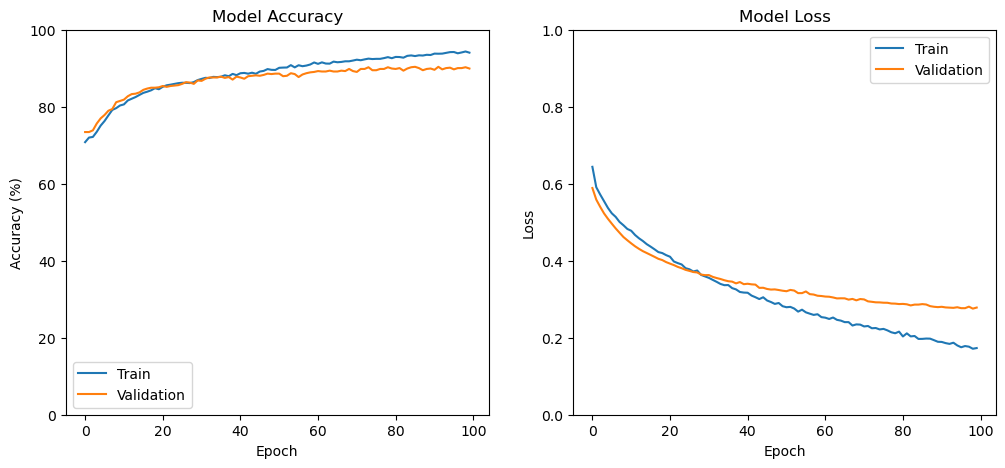

Model saved as final_mix.keras


In [48]:
import numpy as np
import os
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import LSTM, Dense, Input, Dropout, Bidirectional
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

# Load features from the saved .npz file and handle key errors
def load_features(feature_file='features_24gb_sonu.npz'):
    if os.path.exists(feature_file):
        print(f"Loading features from {feature_file}")
        with np.load(feature_file) as data:
            print(f"Available keys in the .npz file: {data.keys()}")  # List available keys
            key = list(data.keys())[0]  # Automatically select the first key or specify the correct key
            features = data[key]  # Access the correct array
        return features
    else:
        raise FileNotFoundError(f"{feature_file} does not exist. Please process the videos to extract features.")

# Build the LSTM-based classification model
def create_model(sequence_length, feature_size):
    video_input = Input(shape=(sequence_length, feature_size))
    
    # Use Bidirectional LSTM
    x = Bidirectional(LSTM(16, return_sequences=False))(video_input)
    x = Dropout(0.3)(x)
    x = Dense(8, activation='relu')(x)
    output = Dense(1, activation='sigmoid')(x)
    
    model = Model(inputs=video_input, outputs=output)
    model.compile(optimizer=Adam(learning_rate=0.00001), loss='binary_crossentropy', metrics=['accuracy'])
    model.summary()
    return model

# Function to plot the training history
def plot_training_history(history):
    plt.figure(figsize=(12, 5))

    # Accuracy plot
    plt.subplot(1, 2, 1)
    plt.plot(np.array(history.history['accuracy']) * 100)  # Scale accuracy to 0-100
    plt.plot(np.array(history.history['val_accuracy']) * 100)  # Scale validation accuracy
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.ylim(0, 100)  # Set y-axis limits between 0 and 100
    plt.legend(['Train', 'Validation'])
    
    # Loss plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.ylim(0, 1)  # Set y-axis limits between 0 and 1 for loss
    plt.legend(['Train', 'Validation'])
    
    plt.show()

# Main function to load features and train the LSTM model
def main(labels, num_frames=10, feature_file='/kaggle/input/features/features.npz'):
    # Load pre-extracted features
    features = load_features(feature_file)
    
    # Convert labels to numpy array
    labels = np.array(labels)

    # Shuffle features and labels
    indices = np.arange(features.shape[0])  # Create an array of indices
    np.random.shuffle(indices)  # Shuffle the indices
    features = features[indices]  # Shuffle features
    labels = labels[indices]      # Shuffle labels
    
    # Create and compile the LSTM model
    model = create_model(sequence_length=num_frames, feature_size=features.shape[-1])
    
    # Set up early stopping
    early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    
    # Train the model using the pre-extracted features
    hist = model.fit(features, labels, epochs=100, batch_size=32, validation_split=0.2, callbacks=[early_stopping])
    print(hist)
    # Plot training history
    plot_training_history(hist)

    # Save the model as 'final_model'
    model.save('final_mix.keras')  # Save the model to a file (in HDF5 format)
    print("Model saved as final_mix.keras")

    return hist

# Load video labels from the CSV
def load_labels(csv_file='video_labels_sonu.csv'):
    file_address = pd.read_csv(csv_file)
    labels = file_address['label'].values
    return labels

if __name__ == "__main__":  # Corrected the if condition
    labels = load_labels('video_labels_final.csv')
    feature_file = 'features_final.npz'
    hist = main(labels, num_frames=10, feature_file=feature_file)


In [5]:
# Prediction

def extract_features_for_prediction(video_path, num_frames=10):
    """
    Extracts features from the video for prediction by first extracting and 
    preprocessing frames, then using the Xception model to get feature vectors.
    """
    # Load the Xception model for feature extraction
    xception_model = load_xception_model()

    # Extract frames with face cropping and resizing
    frames = extract_frames_with_face_crop(video_path, num_frames=num_frames)
    
    # Ensure we have the correct number of frames
    if len(frames) < num_frames:
        print(f"Warning: Only {len(frames)} frames extracted; required {num_frames}.")
        return None
    
    # Extract features
    features = xception_model.predict(frames)
    return np.array(features)


# model_training.py (Additions for Prediction)

# from feature_extraction import extract_features_for_prediction, load_xception_model  # Import feature extraction methods

def load_trained_model(model_path='trained_lstm_model.h5'):
    """
    Load the trained LSTM model.
    """
    if os.path.exists(model_path):
        return tf.keras.models.load_model(model_path)
    else:
        raise FileNotFoundError(f"Trained model file not found at {model_path}")

def predict_video(video_path, num_frames=10, model_path='trained_lstm_model.h5'):
    """
    Predict whether a video is deepfake or real by extracting features and
    using the trained LSTM model to classify.
    """
    # Load the trained LSTM model
    model = load_trained_model(model_path)
    
    # Extract features from the video for prediction
    features = extract_features_for_prediction(video_path, num_frames=num_frames)
    
    # If feature extraction failed, return None
    if features is None:
        print("Failed to extract features for prediction.")
        return None

    # Reshape features to match model input (batch size of 1)
    features = features.reshape(1, num_frames, -1)
    
    # Predict with the model
    prediction = model.predict(features)
    print(prediction)
    # Interpret prediction result
    is_deepfake = prediction[0][0] > 0.5  # Assumes threshold of 0.5 for binary classification
    return "Deepfake" if is_deepfake else "Real"

# Example usage of predict_video function

video_path = r"D:\FF\manipulated_sequences\Deepfakes\c23\videos\000_003.mp4"  # Replace with your video path
prediction = predict_video(video_path, num_frames=10, model_path='final_mix.keras')
print(f"The video is predicted to be: {prediction}")





1/1 [==============================] - 1s 905ms/step
[[0.1371677]]
The video is predicted to be: Real


In [1]:
import numpy as np
print(np.__version__)

1.26.4


In [3]:
pip install tensorflowjs

  Obtaining dependency information for tensorflowjs from https://files.pythonhosted.org/packages/a2/40/c363bdb7ef69b27c941c622b1f6e12eba5e3563abde737690fd1a13969ba/tensorflowjs-4.22.0-py3-none-any.whl.metadata
  Obtaining dependency information for flax>=0.7.2 from https://files.pythonhosted.org/packages/e2/bf/a372898145283e6ecea7fe0d4eabc1416a70e00c6b5b45cd4965445f47a3/flax-0.10.1-py3-none-any.whl.metadata
  Obtaining dependency information for importlib_resources>=5.9.0 from https://files.pythonhosted.org/packages/e1/6a/4604f9ae2fa62ef47b9de2fa5ad599589d28c9fd1d335f32759813dfa91e/importlib_resources-6.4.5-py3-none-any.whl.metadata
  Obtaining dependency information for jax>=0.4.13 from https://files.pythonhosted.org/packages/62/20/6c57c50c0ccc645fea1895950f1e5cd02f961ee44b3ffe83617fa46b0c1d/jax-0.4.35-py3-none-any.whl.metadata
  Obtaining dependency information for jaxlib>=0.4.13 from https://files.pythonhosted.org/packages/7d/7c/73a4c4a34f2bbfce63e8baefee11753b0d58a71e0d2c33f210e00e

ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'C:\\Users\\DDU College-DELHI\\anaconda3\\Lib\\site-packages\\~-_dtypes\\_ml_dtypes_ext.cp311-win_amd64.pyd'
Consider using the `--user` option or check the permissions.



In [1]:
import tensorflow as tf
import tensorflowjs as tfjs

model = tf.kera.models.load_model('final_mix.keras')
tfjs.converters.save_keras_model(model, '/js')

ModuleNotFoundError: No module named 'tensorflowjs'

In [1]:
pip show tensorflowjs

Note: you may need to restart the kernel to use updated packages.
